# LoRA vs QLoRA: parameter-efficient fine-tuning benchmark

Antoine Théologien — MSc MIND, Sorbonne University

### Prérequis

In [ ]:
%pip install accelerate==1.12.0
%pip install bertviz==1.4.1
%pip install datasets==4.4.1
%pip install evaluate==0.4.6
%pip install gensim==4.4.0
%pip install matplotlib==3.10.7
%pip install outlines==1.2.9
%pip install pandas==2.3.3
%pip install peft==0.18.0
%pip install scikit-learn==1.7.2
%pip install seaborn==0.13.2
%pip install torch==2.9.1
%pip install transformers==4.57.1
%pip install bitsandbytes

In [ ]:
import torch
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import evaluate
from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding,
    BitsAndBytesConfig
)
from peft import LoraConfig, get_peft_model, TaskType, prepare_model_for_kbit_training


def get_best_device():

    if torch.cuda.is_available():
        device = torch.device("cuda")
        total_memory = torch.cuda.get_device_properties(device).total_memory
        print(f"GPU Memory: {total_memory / 1e9:.1f} GB")
        print(f"GPU Name: {torch.cuda.get_device_name(device)}")
    elif torch.backends.mps.is_available():
        device = torch.device("mps")
    else:
        device = torch.device("cpu")
    print(f"Found device: {device}")
    return device


device = get_best_device()

MODEL_NAME = "distilbert-base-uncased-finetuned-sst-2-english"

print("Loading pre-trained sentiment classifier...")
classifier_model_name = "distilbert-base-uncased-finetuned-sst-2-english"
classifier_tokenizer = AutoTokenizer.from_pretrained(classifier_model_name)
classifier_model = AutoModelForSequenceClassification.from_pretrained(
    classifier_model_name
).to(device)

print(f"Model: {classifier_model_name}")
print(f"Parameters: {sum(p.numel() for p in classifier_model.parameters()):,}")

print("Loading IMDb dataset...")
dataset = load_dataset("imdb", split="train")
dataset = dataset.map(lambda x: {"labels": x.pop("label")})

dataset = dataset.shuffle(seed=42)

dataset_size = 10_000
eval_split = 0.05


dataset = dataset.select(range(dataset_size))

train_val = dataset.train_test_split(test_size=eval_split, seed=42)
train_dataset = train_val["train"]
eval_dataset = train_val["test"]

print(f"Train: {len(train_dataset)}, Eval: {len(eval_dataset)}")

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def preprocess_function(examples):
    return classifier_tokenizer(
        examples["text"], truncation=True, max_length=256, padding="max_length"
    )

train_dataset = train_dataset.map(preprocess_function, batched=True)
eval_dataset = eval_dataset.map(preprocess_function, batched=True)

train_dataset.set_format("torch", columns=["input_ids", "attention_mask", "labels"])
eval_dataset.set_format("torch", columns=["input_ids", "attention_mask", "labels"])

print(
    f"Datasets tokenized with {len(train_dataset[0]['input_ids'])} tokens per example"
)

data_collator = DataCollatorWithPadding(tokenizer=classifier_tokenizer)


GPU Memory: 15.8 GB
GPU Name: Tesla T4
Found device: cuda
Loading pre-trained sentiment classifier...
Model: distilbert-base-uncased-finetuned-sst-2-english
Parameters: 66,955,010
Loading IMDb dataset...
Train: 9500, Eval: 500
Datasets tokenized with 256 tokens per example


In [ ]:
class ProjectBenchmark:
    def __init__(self):
        self.results = {}
        self.metric = evaluate.load("accuracy")

    def compute_metrics(self, eval_pred):
        logits, labels = eval_pred
        predictions = np.argmax(logits, axis=-1)
        return self.metric.compute(predictions=predictions, references=labels)

    def get_memory(self):
        if torch.cuda.is_available():
            torch.cuda.synchronize()
            return torch.cuda.max_memory_allocated() / 1024**3
        return 0

    def cleanup(self):
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
            torch.cuda.reset_peak_memory_stats()

    def run(self, name, model, batch_size=16, lr=2e-4, epochs=1):
        print(f"\n=== Benchmark : {name} ===")
        self.cleanup()
        mem_start = self.get_memory()

        args = TrainingArguments(
            output_dir=f"results_{name.replace(' ', '_')}",
            per_device_train_batch_size=batch_size,
            num_train_epochs=epochs,
            learning_rate=lr,
            logging_steps=10,
            eval_strategy="epoch",
            save_strategy="no",
            fp16=(device.type == "cuda"),
            report_to="none"
        )

        trainer = Trainer(
            model=model, args=args,
            train_dataset=train_dataset,
            eval_dataset=eval_dataset,
            tokenizer=tokenizer,
            data_collator=data_collator,
            compute_metrics=self.compute_metrics
        )

        start_t = time.time()
        trainer.train()
        train_time = time.time() - start_t
        mem_used = self.get_memory() - mem_start

        eval_res = trainer.evaluate()
        acc = eval_res["eval_accuracy"]

        print("Test vitesse d'inférence...")

        batch = eval_dataset[:50]

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)

        start_inf = time.time()
        with torch.no_grad():
            model(input_ids=input_ids, attention_mask=attention_mask)
        inf_speed = 50 / (time.time() - start_inf)

        self.results[name] = {
            "Training Time (s)": round(train_time, 2),
            "Memory (GB)": round(mem_used, 2),
            "Inference (samp/s)": round(inf_speed, 1),
            "Accuracy": round(acc, 3),
            "Params (M)": round(model.num_parameters(only_trainable=True)/1e6, 4)
        }

        del model, trainer
        self.cleanup()
        return self.results[name]

benchmark = ProjectBenchmark()

# Première expérience : baseline

In [ ]:
print("--- Config 1 : Full Fine-Tuning ---")
model_baseline = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2).to(device)

benchmark.run("Baseline (Full)", model_baseline, lr=2e-5)

--- Config 1 : Full Fine-Tuning ---

=== Benchmark : Baseline (Full) ===


/tmp/ipython-input-2347295159.py:39: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(


Epoch,Training Loss,Validation Loss,Accuracy
1,0.275800,0.233635,0.906000


Test vitesse d'inférence...


{'Training Time (s)': 77.71,
 'Memory (GB)': 1.16,
 'Inference (samp/s)': 5159.3,
 'Accuracy': 0.906,
 'Params (M)': 66.955}

# Deuxième expérience : PEFT LoRA

In [ ]:
print("--- Config 2 : LoRA ---")
model_base = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2).to(device)

peft_config = LoraConfig(
    task_type=TaskType.SEQ_CLS,
    r=8,
    lora_alpha=16,
    lora_dropout=0.1,
    target_modules=["q_lin", "v_lin"]
)

model_lora = get_peft_model(model_base, peft_config)
model_lora.print_trainable_parameters()

benchmark.run("LoRA", model_lora, lr=2e-4)

--- Config 2 : LoRA ---
trainable params: 739,586 || all params: 67,694,596 || trainable%: 1.0925

=== Benchmark : LoRA ===


/tmp/ipython-input-2347295159.py:39: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(


Epoch,Training Loss,Validation Loss,Accuracy
1,0.260300,0.238892,0.912000


Test vitesse d'inférence...


{'Training Time (s)': 49.47,
 'Memory (GB)': 0.0,
 'Inference (samp/s)': 4286.2,
 'Accuracy': 0.912,
 'Params (M)': 0.7396}

# Troisième Expérience : QLoRA (4 bit + LoRA)

In [ ]:
print("--- Config 3 : QLoRA (4-bit) ---")
if device.type == "cuda":
    bnb_config = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_compute_dtype=torch.float16,
        llm_int8_skip_modules=["classifier", "pre_classifier"]
    )

    model_qlora_base = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME,
        num_labels=2,
        quantization_config=bnb_config
    )

    model_qlora_base = prepare_model_for_kbit_training(model_qlora_base)

    peft_config_qlora = LoraConfig(
        task_type=TaskType.SEQ_CLS,
        r=8,
        lora_alpha=16,
        lora_dropout=0.1,
        target_modules=["q_lin", "v_lin"],
        modules_to_save=["classifier", "pre_classifier"]
    )

    model_qlora = get_peft_model(model_qlora_base, peft_config_qlora)
    model_qlora.print_trainable_parameters()

    benchmark.run("QLoRA", model_qlora, lr=2e-4)
    print(benchmark.results["QLoRA"])


--- Config 3 : QLoRA (4-bit) ---
trainable params: 739,586 || all params: 67,694,596 || trainable%: 1.0925

=== Benchmark : QLoRA ===


/tmp/ipython-input-2347295159.py:39: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(
/usr/local/lib/python3.12/dist-packages/torch/_dynamo/eval_frame.py:1044: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


Epoch,Training Loss,Validation Loss,Accuracy
1,0.242800,0.241460,0.908000


Test vitesse d'inférence...
{'Training Time (s)': 94.72, 'Memory (GB)': 0.21, 'Inference (samp/s)': 2446.8, 'Accuracy': 0.908, 'Params (M)': 0.7396}


# Comparaison des résultats

Colonnes disponibles : ['Training Time (s)', 'Memory (GB)', 'Inference (samp/s)', 'Accuracy', 'Params (M)']


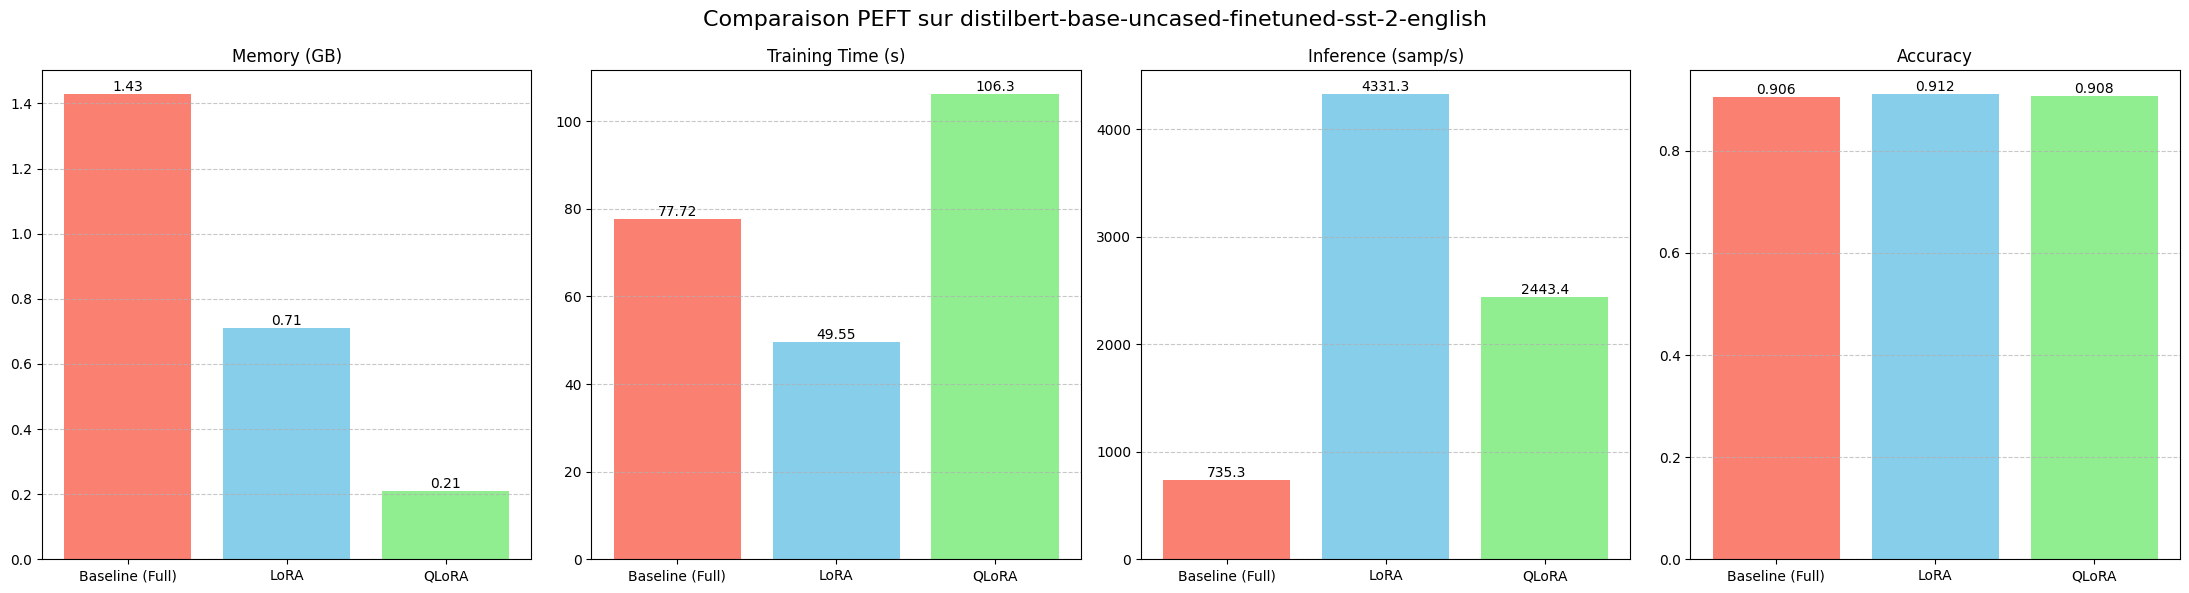

In [ ]:
print("Colonnes disponibles :", df.columns.tolist())

metrics = ["Memory (GB)", "Training Time (s)", "Inference (samp/s)", "Accuracy"]

fig, axes = plt.subplots(1, 4, figsize=(22, 6))
fig.suptitle(f"Comparaison PEFT sur {MODEL_NAME}", fontsize=16)

colors = ['salmon', 'skyblue', 'lightgreen']

for i, metric in enumerate(metrics):
    if metric in df.columns:
        ax = axes[i]
        bars = ax.bar(df.index, df[metric], color=colors[:len(df)])

        ax.set_title(metric)

        ax.grid(axis='y', linestyle='--', alpha=0.7)

        for bar in bars:
            h = bar.get_height()
            ax.text(bar.get_x() + bar.get_width()/2, h, f'{h}', ha='center', va='bottom')
    else:
        axes[i].set_visible(False)

plt.tight_layout()
plt.show()

# Analyse de sensibilité pour LoRA et QLoRA

In [ ]:

ranks_to_test = [4, 8, 16, 32, 64, 128]
print(f"Lancement de l'analyse de sensibilité sur les rangs : {ranks_to_test}")

for r in ranks_to_test:
    print(f"\n--- Test LoRA avec r={r} ---")
    model_base = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2).to(device)

    config = LoraConfig(
        task_type=TaskType.SEQ_CLS,
        r=r,
        lora_alpha=r * 2,
        lora_dropout=0.1,
        target_modules=["q_lin", "v_lin"]
    )

    model = get_peft_model(model_base, config)
    benchmark.run(f"LoRA_r{r}", model, lr=2e-4)

if device.type == "cuda":
    for r in ranks_to_test:
        print(f"\n--- Test QLoRA avec r={r} ---")

        bnb_config = BitsAndBytesConfig(
            load_in_4bit=True,
            bnb_4bit_quant_type="nf4",
            bnb_4bit_compute_dtype=torch.float16,
            llm_int8_skip_modules=["classifier", "pre_classifier"]
        )

        model_qbase = AutoModelForSequenceClassification.from_pretrained(
            MODEL_NAME, num_labels=2, quantization_config=bnb_config
        )
        model_qbase = prepare_model_for_kbit_training(model_qbase)

        config = LoraConfig(
            task_type=TaskType.SEQ_CLS,
            r=r,
            lora_alpha=r * 2,
            lora_dropout=0.1,
            target_modules=["q_lin", "v_lin"],
            modules_to_save=["classifier", "pre_classifier"]
        )

        model = get_peft_model(model_qbase, config)
        benchmark.run(f"QLoRA_r{r}", model, lr=2e-4)

Lancement de l'analyse de sensibilité sur les rangs : [4, 8, 16, 32, 64, 128]

--- Test LoRA avec r=4 ---

=== Benchmark : LoRA_r4 ===


/tmp/ipython-input-2347295159.py:39: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(


Epoch,Training Loss,Validation Loss,Accuracy
1,0.261500,0.240823,0.906000


Test vitesse d'inférence...

--- Test LoRA avec r=8 ---

=== Benchmark : LoRA_r8 ===


/tmp/ipython-input-2347295159.py:39: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(


Epoch,Training Loss,Validation Loss,Accuracy
1,0.260300,0.238892,0.912000


... (27 outputs left out)

Test vitesse d'inférence...

--- Test QLoRA avec r=128 ---

=== Benchmark : QLoRA_r128 ===


/tmp/ipython-input-2347295159.py:39: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(
/usr/local/lib/python3.12/dist-packages/torch/_dynamo/eval_frame.py:1044: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


Epoch,Training Loss,Validation Loss,Accuracy
1,0.235200,0.233065,0.912000


Test vitesse d'inférence...


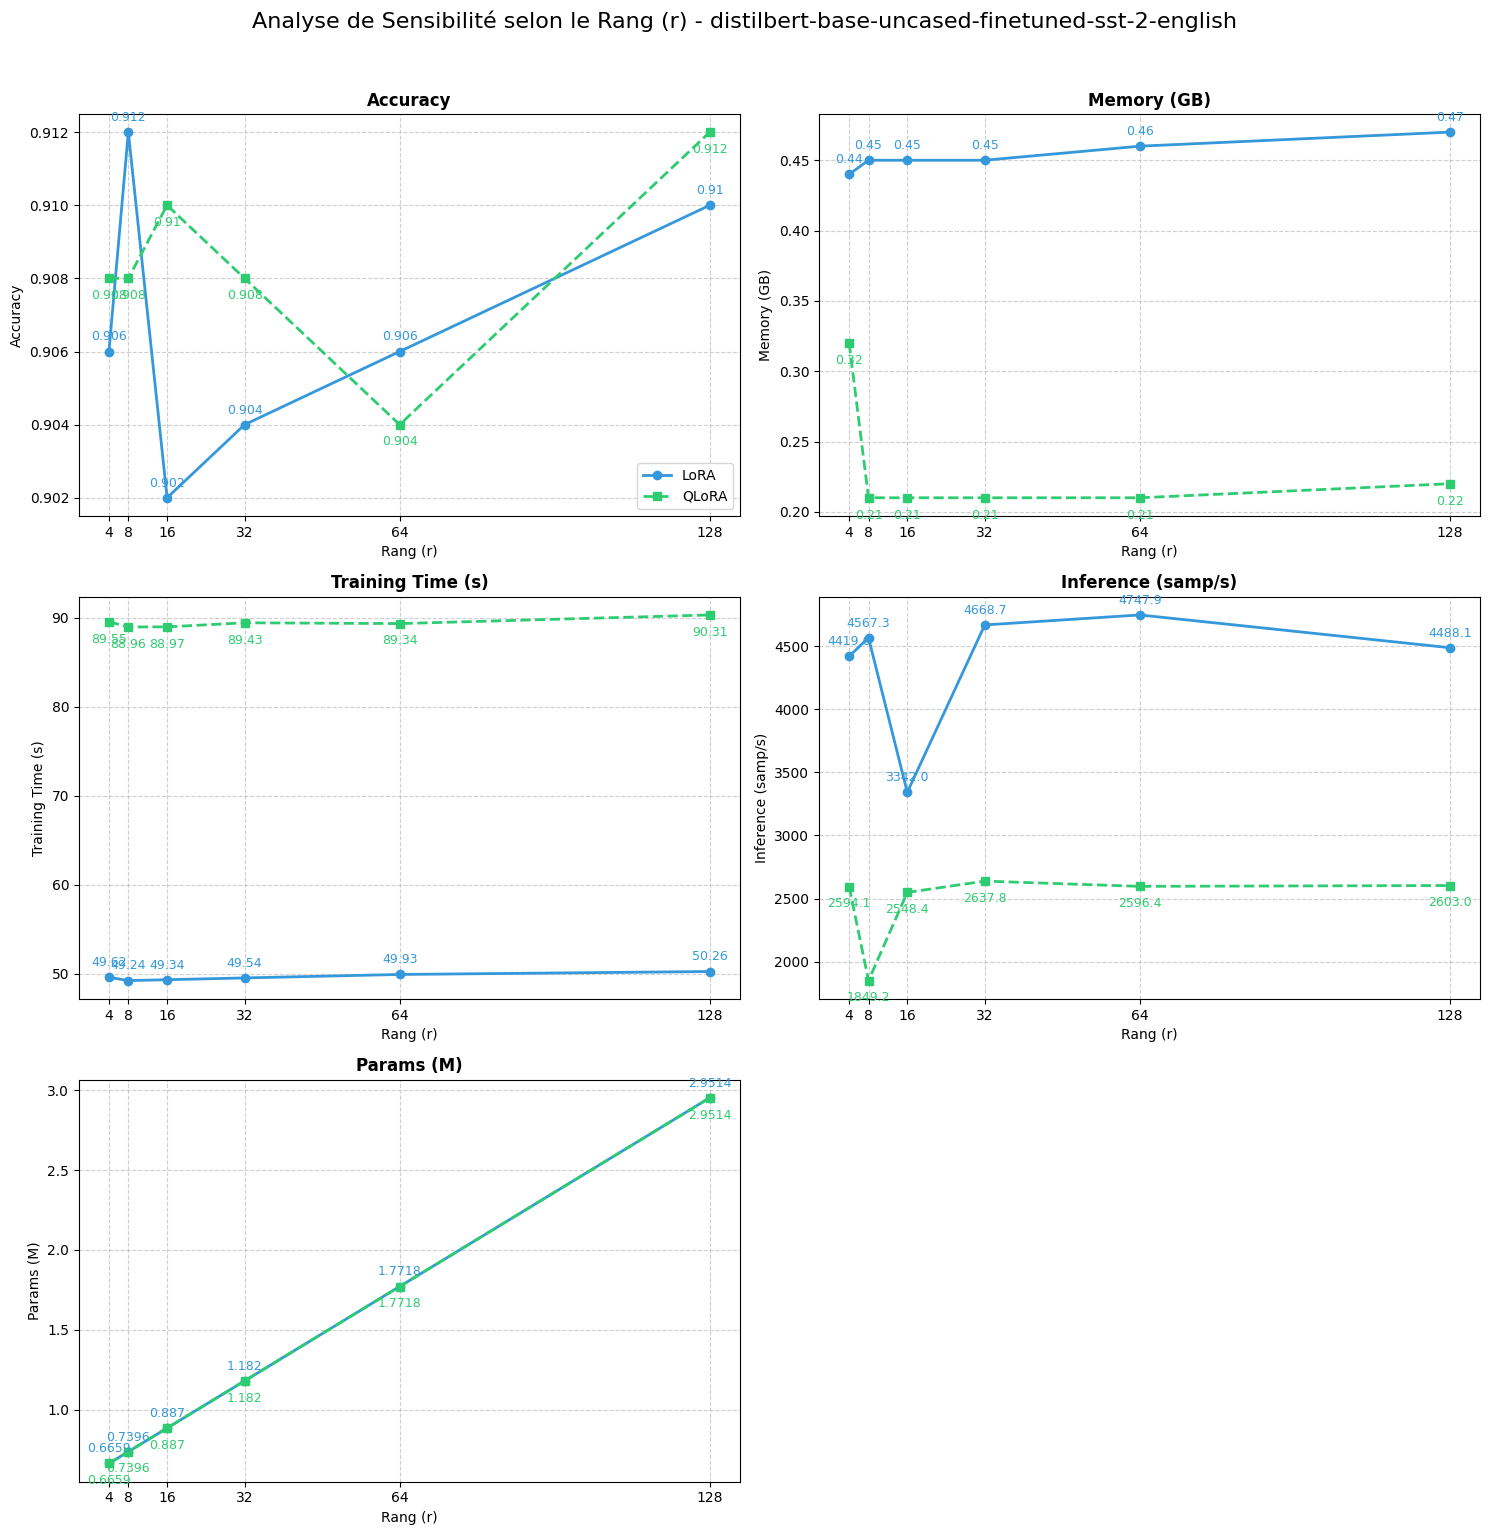

In [ ]:
import matplotlib.pyplot as plt
import math

metrics_to_analyze = [
    "Accuracy",
    "Memory (GB)",
    "Training Time (s)",
    "Inference (samp/s)",
    "Params (M)"
]

ranks = [4, 8, 16, 32, 64, 128]

num_metrics = len(metrics_to_analyze)
cols = 2
rows = math.ceil(num_metrics / cols)

fig, axes = plt.subplots(rows, cols, figsize=(15, 5 * rows))
fig.suptitle(f"Analyse de Sensibilité selon le Rang (r) - {MODEL_NAME}", fontsize=16, y=1.02)

axes = axes.flatten()

for i, metric in enumerate(metrics_to_analyze):
    ax = axes[i]

    lora_data = [benchmark.results.get(f"LoRA_r{r}", {}).get(metric, None) for r in ranks]
    qlora_data = [benchmark.results.get(f"QLoRA_r{r}", {}).get(metric, None) for r in ranks]

    valid_ranks_lora = [r for r, d in zip(ranks, lora_data) if d is not None]
    valid_data_lora = [d for d in lora_data if d is not None]

    valid_ranks_qlora = [r for r, d in zip(ranks, qlora_data) if d is not None]
    valid_data_qlora = [d for d in qlora_data if d is not None]

    if valid_data_lora:
        ax.plot(valid_ranks_lora, valid_data_lora, marker='o', label='LoRA', color='#3498db', linewidth=2)
        for r, val in zip(valid_ranks_lora, valid_data_lora):
            ax.annotate(f"{val}", (r, val), textcoords="offset points", xytext=(0, 8), ha='center', fontsize=9, color='#3498db')

    if valid_data_qlora:
        ax.plot(valid_ranks_qlora, valid_data_qlora, marker='s', label='QLoRA', color='#2ecc71', linewidth=2, linestyle='--')
        for r, val in zip(valid_ranks_qlora, valid_data_qlora):
            ax.annotate(f"{val}", (r, val), textcoords="offset points", xytext=(0, -15), ha='center', fontsize=9, color='#2ecc71')

    ax.set_title(metric, fontsize=12, fontweight='bold')
    ax.set_xlabel("Rang (r)")
    ax.set_ylabel(metric)
    ax.set_xticks(ranks)
    ax.grid(True, linestyle='--', alpha=0.6)

    if i == 0:
        ax.legend()

for j in range(i + 1, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

# Seconde dataset : AG-NEWS - Classification multi-classe

In [ ]:
print("--- Préparation du dataset AG News ---")

dataset_ag = load_dataset("ag_news")

train_subset_ag = dataset_ag["train"].shuffle(seed=42).select(range(2000))
eval_subset_ag = dataset_ag["test"].shuffle(seed=42).select(range(500))

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def preprocess_function(examples):
    return tokenizer(examples["text"], truncation=True, max_length=256, padding="max_length")

tokenized_train_ag = train_subset_ag.map(preprocess_function, batched=True)
tokenized_eval_ag = eval_subset_ag.map(preprocess_function, batched=True)

tokenized_train_ag.set_format("torch", columns=["input_ids", "attention_mask", "label"])
tokenized_eval_ag.set_format("torch", columns=["input_ids", "attention_mask", "label"])

print(f"Dataset AG News prêt. Train: {len(tokenized_train_ag)}, Eval: {len(tokenized_eval_ag)}")
print("Classes : 4 (World, Sports, Business, Sci/Tech)")

--- Préparation du dataset AG News ---


Map:   0%|          | 0/500 [00:00<?, ? examples/s]

Dataset AG News prêt. Train: 2000, Eval: 500
Classes : 4 (World, Sports, Business, Sci/Tech)


In [ ]:
benchmark_ag = ProjectBenchmark()

def run_ag_experiment(name, model, batch_size=16, lr=2e-4):
    print(f"\n=== Benchmark AG News : {name} ===")
    benchmark_ag.cleanup()
    mem_start = benchmark_ag.get_memory()

    args = TrainingArguments(
        output_dir=f"results_ag_{name}",
        per_device_train_batch_size=batch_size,
        num_train_epochs=1,
        learning_rate=lr,
        logging_steps=50,
        eval_strategy="epoch",
        save_strategy="no",
        fp16=(device.type == "cuda"),
        report_to="none"
    )

    trainer = Trainer(
        model=model,
        args=args,
        train_dataset=tokenized_train_ag,
        eval_dataset=tokenized_eval_ag,
        tokenizer=tokenizer,
        data_collator=data_collator,
        compute_metrics=benchmark_ag.compute_metrics
    )

    # Training
    start_t = time.time()
    trainer.train()
    train_time = time.time() - start_t
    mem_used = benchmark_ag.get_memory() - mem_start

    eval_res = trainer.evaluate()
    acc = eval_res["eval_accuracy"]

    batch = tokenized_eval_ag[:50]
    input_ids = batch["input_ids"].to(device)
    attention_mask = batch["attention_mask"].to(device)

    start_inf = time.time()
    with torch.no_grad():
        model(input_ids=input_ids, attention_mask=attention_mask)
    inf_speed = 50 / (time.time() - start_inf)

    benchmark_ag.results[name] = {
        "Training Time (s)": round(train_time, 2),
        "Memory (GB)": round(mem_used, 2),
        "Inference (samp/s)": round(inf_speed, 1),
        "Accuracy": round(acc, 3),
        "Params (M)": round(model.num_parameters(only_trainable=True)/1e6, 4)
    }

    del model, trainer
    benchmark_ag.cleanup()
    return benchmark_ag.results[name]

In [ ]:
print("--- Config 1 : Full Fine-Tuning (4 classes) ---")
model_baseline = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=4,
    ignore_mismatched_sizes=True
).to(device)

run_ag_experiment("Baseline (AG)", model_baseline, lr=5e-5)

print("\n--- Config 2 : LoRA (4 classes) ---")
model_base = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=4,
    ignore_mismatched_sizes=True
).to(device)

peft_config = LoraConfig(
    task_type=TaskType.SEQ_CLS, r=16, lora_alpha=32, lora_dropout=0.1,
    target_modules=["q_lin", "v_lin"]
)
model_lora = get_peft_model(model_base, peft_config)
run_ag_experiment("LoRA (AG)", model_lora, lr=5e-4)

print("\n--- Config 3 : QLoRA (4 classes) ---")
if device.type == "cuda":
    bnb_config = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_compute_dtype=torch.float16,
        llm_int8_skip_modules=["classifier", "pre_classifier"]
    )
    model_qlora_base = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME,
        num_labels=4,
        quantization_config=bnb_config,
        ignore_mismatched_sizes=True
    )
    model_qlora_base = prepare_model_for_kbit_training(model_qlora_base)

    peft_config_qlora = LoraConfig(
        task_type=TaskType.SEQ_CLS, r=16, lora_alpha=32, lora_dropout=0.1,
        target_modules=["q_lin", "v_lin"],
        modules_to_save=["classifier", "pre_classifier"]
    )

    model_qlora = get_peft_model(model_qlora_base, peft_config_qlora)
    run_ag_experiment("QLoRA (AG)", model_qlora, lr=5e-4)
else:
    print("Pas de GPU pour QLoRA")

--- Config 1 : Full Fine-Tuning (4 classes) ---


Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased-finetuned-sst-2-english and are newly initialized because the shapes did not match:
- classifier.bias: found shape torch.Size([2]) in the checkpoint and torch.Size([4]) in the model instantiated
- classifier.weight: found shape torch.Size([2, 768]) in the checkpoint and torch.Size([4, 768]) in the model instantiated
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/tmp/ipython-input-4087506744.py:20: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(



=== Benchmark AG News : Baseline (AG) ===


Epoch,Training Loss,Validation Loss,Accuracy
1,0.387100,0.386091,0.880000



--- Config 2 : LoRA (4 classes) ---


Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased-finetuned-sst-2-english and are newly initialized because the shapes did not match:
- classifier.bias: found shape torch.Size([2]) in the checkpoint and torch.Size([4]) in the model instantiated
- classifier.weight: found shape torch.Size([2, 768]) in the checkpoint and torch.Size([4, 768]) in the model instantiated
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/tmp/ipython-input-4087506744.py:20: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(


... (3 outputs left out)

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased-finetuned-sst-2-english and are newly initialized because the shapes did not match:
- classifier.bias: found shape torch.Size([2]) in the checkpoint and torch.Size([4]) in the model instantiated
- classifier.weight: found shape torch.Size([2, 768]) in the checkpoint and torch.Size([4, 768]) in the model instantiated
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/tmp/ipython-input-4087506744.py:20: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(



=== Benchmark AG News : QLoRA (AG) ===


/usr/local/lib/python3.12/dist-packages/torch/_dynamo/eval_frame.py:1044: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


Epoch,Training Loss,Validation Loss,Accuracy
1,0.399300,0.384791,0.874000



=== RÉSULTATS GÉNÉRALISATION (AG NEWS) ===


,Training Time (s),Memory (GB),Inference (samp/s),Accuracy,Params (M)
Baseline (AG),14.67,1.14,6470.3,0.880,66.9565
LoRA (AG),11.55,0.46,3449.3,0.872,0.8886
QLoRA (AG),20.31,0.22,2702.3,0.874,0.8886


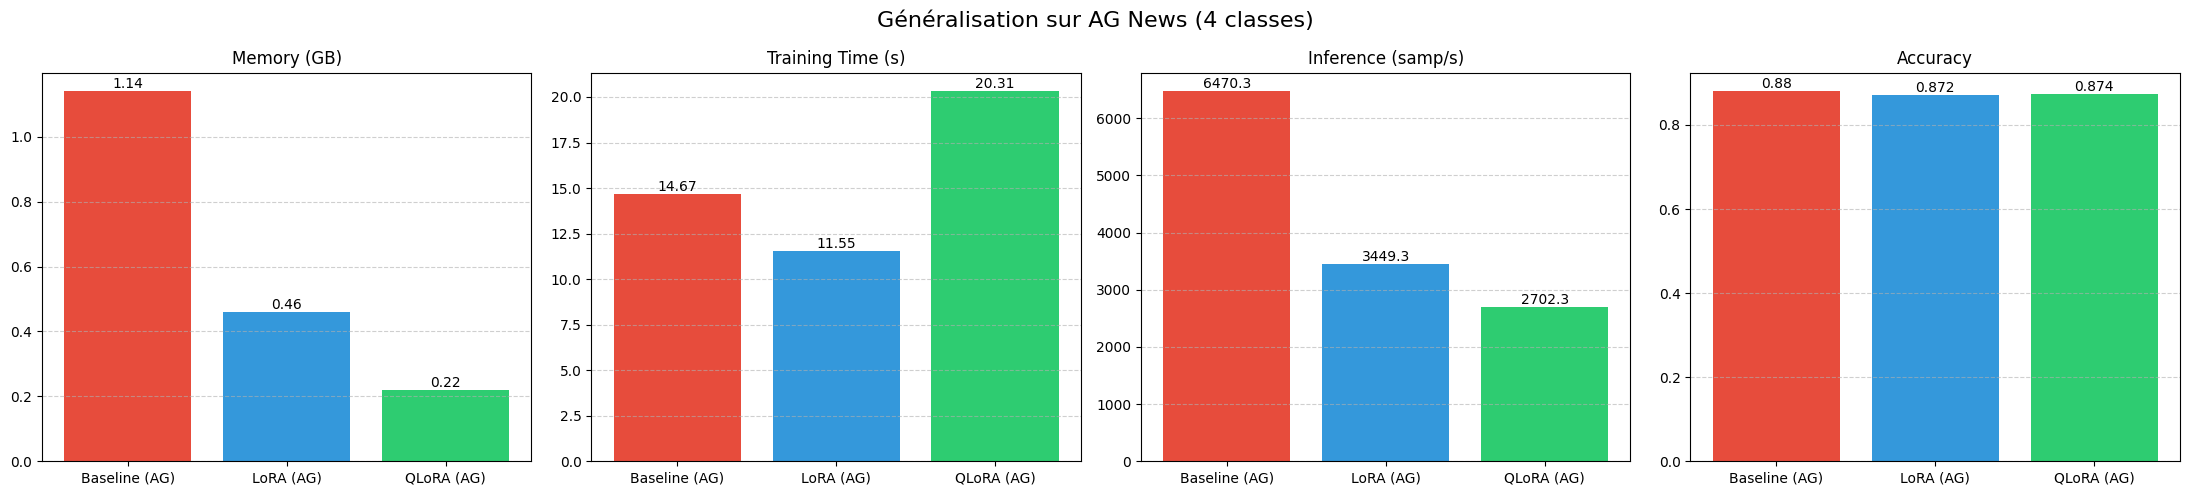

In [ ]:
df_ag = pd.DataFrame(benchmark_ag.results).T
print("\n=== RÉSULTATS GÉNÉRALISATION (AG NEWS) ===")
display(df_ag)

metrics = ["Memory (GB)", "Training Time (s)", "Inference (samp/s)", "Accuracy"]
fig, axes = plt.subplots(1, 4, figsize=(22, 5))
fig.suptitle(f"Généralisation sur AG News (4 classes)", fontsize=16)
colors = ['#e74c3c', '#3498db', '#2ecc71']

for i, metric in enumerate(metrics):
    if metric in df_ag.columns:
        ax = axes[i]
        bars = ax.bar(df_ag.index, df_ag[metric], color=colors[:len(df_ag)])
        ax.set_title(metric)
        ax.grid(axis='y', linestyle='--', alpha=0.6)
        for bar in bars:
            h = bar.get_height()
            ax.text(bar.get_x() + bar.get_width()/2, h, f'{h}', ha='center', va='bottom')

plt.tight_layout()
plt.show()

In [ ]:

ranks_to_test = [4, 8, 16, 32, 64, 128]

for r in ranks_to_test:
    print(f"\n--- Test LoRA (AG) r={r} ---")
    model_base = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=4, ignore_mismatched_sizes=True
    ).to(device)

    config = LoraConfig(
        task_type=TaskType.SEQ_CLS,
        r=r,
        lora_alpha=r * 2,
        lora_dropout=0.1,
        target_modules=["q_lin", "v_lin"]
    )

    model = get_peft_model(model_base, config)
    run_ag_experiment(f"LoRA_AG_r{r}", model, lr=5e-4)

    if device.type == "cuda":
        print(f"--- Test QLoRA (AG) r={r} ---")
        bnb_config = BitsAndBytesConfig(
            load_in_4bit=True,
            bnb_4bit_quant_type="nf4",
            bnb_4bit_compute_dtype=torch.float16,
            llm_int8_skip_modules=["classifier", "pre_classifier"]
        )

        model_qbase = AutoModelForSequenceClassification.from_pretrained(
            MODEL_NAME, num_labels=4, quantization_config=bnb_config, ignore_mismatched_sizes=True
        )
        model_qbase = prepare_model_for_kbit_training(model_qbase)

        config_q = LoraConfig(
            task_type=TaskType.SEQ_CLS,
            r=r,
            lora_alpha=r * 2,
            lora_dropout=0.1,
            target_modules=["q_lin", "v_lin"],
            modules_to_save=["classifier", "pre_classifier"]
        )

        model_q = get_peft_model(model_qbase, config_q)
        run_ag_experiment(f"QLoRA_AG_r{r}", model_q, lr=5e-4)


--- Test LoRA (AG) r=4 ---


Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased-finetuned-sst-2-english and are newly initialized because the shapes did not match:
- classifier.bias: found shape torch.Size([2]) in the checkpoint and torch.Size([4]) in the model instantiated
- classifier.weight: found shape torch.Size([2, 768]) in the checkpoint and torch.Size([4, 768]) in the model instantiated
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/tmp/ipython-input-4087506744.py:20: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(



=== Benchmark AG News : LoRA_AG_r4 ===


Epoch,Training Loss,Validation Loss,Accuracy
1,0.406100,0.401944,0.870000


--- Test QLoRA (AG) r=4 ---


Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased-finetuned-sst-2-english and are newly initialized because the shapes did not match:
- classifier.bias: found shape torch.Size([2]) in the checkpoint and torch.Size([4]) in the model instantiated
- classifier.weight: found shape torch.Size([2, 768]) in the checkpoint and torch.Size([4, 768]) in the model instantiated
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/tmp/ipython-input-4087506744.py:20: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(


... (44 outputs left out)

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased-finetuned-sst-2-english and are newly initialized because the shapes did not match:
- classifier.bias: found shape torch.Size([2]) in the checkpoint and torch.Size([4]) in the model instantiated
- classifier.weight: found shape torch.Size([2, 768]) in the checkpoint and torch.Size([4, 768]) in the model instantiated
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/tmp/ipython-input-4087506744.py:20: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(



=== Benchmark AG News : QLoRA_AG_r128 ===


/usr/local/lib/python3.12/dist-packages/torch/_dynamo/eval_frame.py:1044: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


Epoch,Training Loss,Validation Loss,Accuracy
1,0.386000,0.358426,0.882000


,Training Time (s),Memory (GB),Inference (samp/s),Accuracy,Params (M)
LoRA_AG_r4,11.52,0.70,4016.1,0.870,0.6674
QLoRA_AG_r4,20.23,0.18,2546.9,0.874,0.6674
LoRA_AG_r8,11.44,0.45,4175.2,0.878,0.7411
QLoRA_AG_r8,20.30,0.21,2475.3,0.876,0.7411
LoRA_AG_r16,11.49,0.45,4440.2,0.872,0.8886
QLoRA_AG_r16,20.26,0.22,2691.1,0.874,0.8886
LoRA_AG_r32,11.49,0.45,3442.1,0.870,1.1835
QLoRA_AG_r32,20.20,0.22,2583.5,0.878,1.1835
LoRA_AG_r64,11.55,0.46,4378.0,0.870,1.7733
QLoRA_AG_r64,20.21,0.22,2730.3,0.878,1.7733


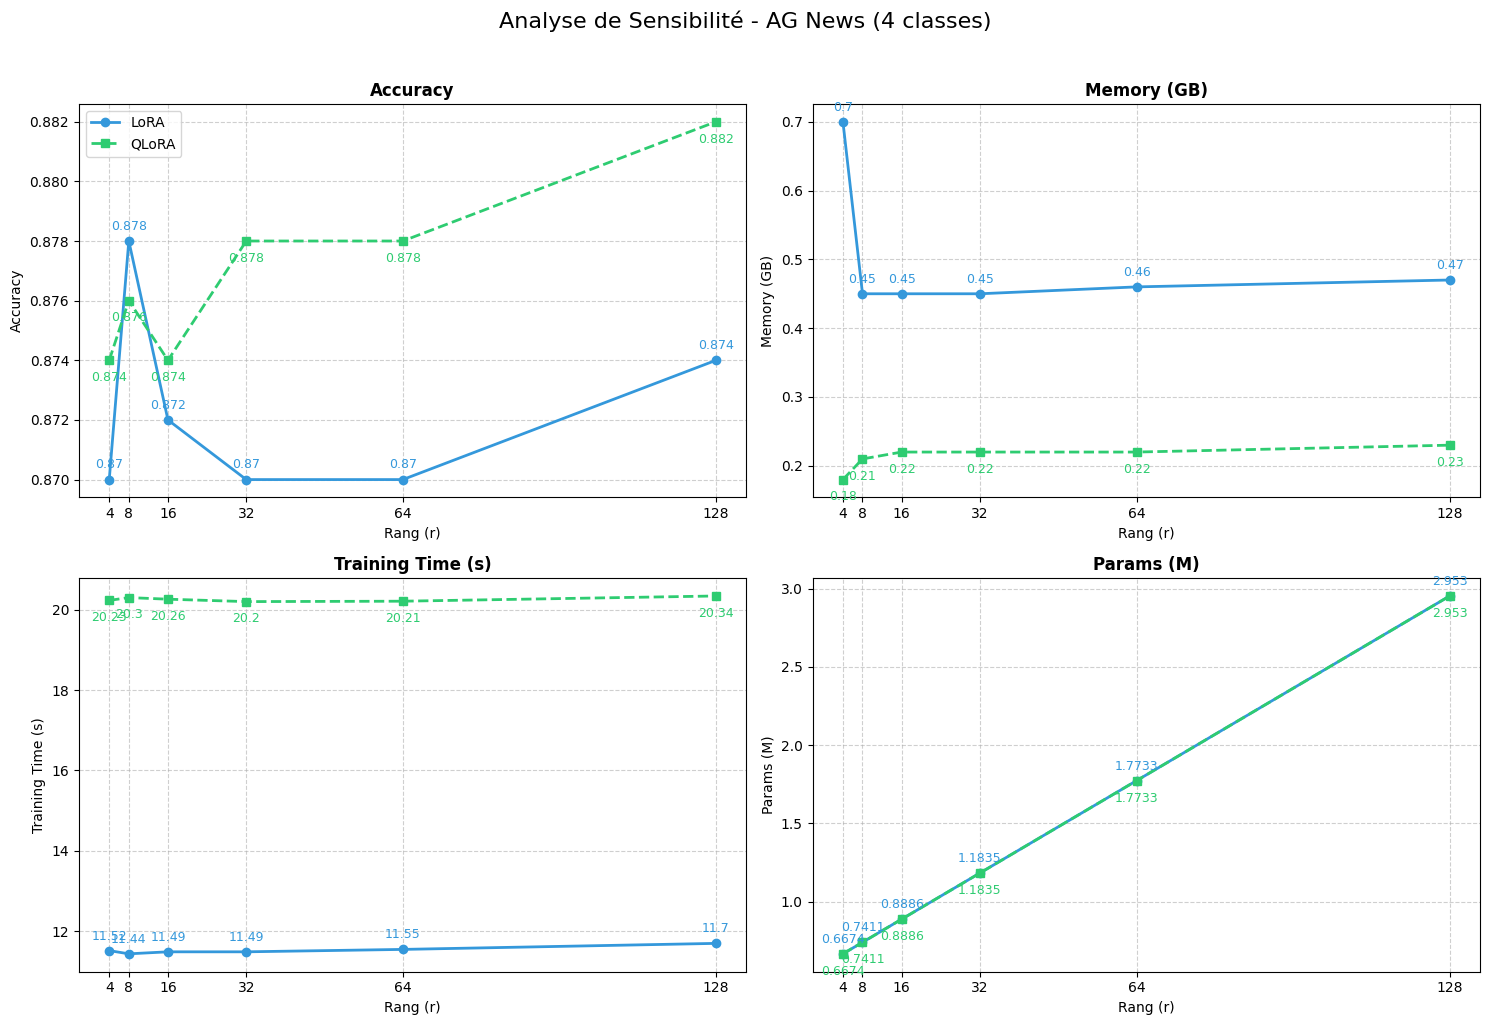

In [ ]:
import matplotlib.pyplot as plt
import math

df_ag_ranks = pd.DataFrame(benchmark_ag.results).T

df_ag_ranks = df_ag_ranks[df_ag_ranks.index.str.contains("_AG_r")]

display(df_ag_ranks)

metrics_to_analyze = ["Accuracy", "Memory (GB)", "Training Time (s)", "Params (M)"]
ranks = [4, 8, 16, 32, 64, 128]

num_metrics = len(metrics_to_analyze)
cols = 2
rows = math.ceil(num_metrics / cols)

fig, axes = plt.subplots(rows, cols, figsize=(15, 5 * rows))
fig.suptitle(f"Analyse de Sensibilité - AG News (4 classes)", fontsize=16, y=1.02)
axes = axes.flatten()

for i, metric in enumerate(metrics_to_analyze):
    ax = axes[i]

    lora_data = [benchmark_ag.results.get(f"LoRA_AG_r{r}", {}).get(metric, None) for r in ranks]
    qlora_data = [benchmark_ag.results.get(f"QLoRA_AG_r{r}", {}).get(metric, None) for r in ranks]

    valid_ranks_lora = [r for r, d in zip(ranks, lora_data) if d is not None]
    valid_data_lora = [d for d in lora_data if d is not None]

    valid_ranks_qlora = [r for r, d in zip(ranks, qlora_data) if d is not None]
    valid_data_qlora = [d for d in qlora_data if d is not None]

    if valid_data_lora:
        ax.plot(valid_ranks_lora, valid_data_lora, marker='o', label='LoRA', color='#3498db', linewidth=2)
        for r, val in zip(valid_ranks_lora, valid_data_lora):
            ax.annotate(f"{val}", (r, val), textcoords="offset points", xytext=(0, 8), ha='center', fontsize=9, color='#3498db')

    if valid_data_qlora:
        ax.plot(valid_ranks_qlora, valid_data_qlora, marker='s', label='QLoRA', color='#2ecc71', linewidth=2, linestyle='--')
        for r, val in zip(valid_ranks_qlora, valid_data_qlora):
            ax.annotate(f"{val}", (r, val), textcoords="offset points", xytext=(0, -15), ha='center', fontsize=9, color='#2ecc71')

    ax.set_title(metric, fontsize=12, fontweight='bold')
    ax.set_xlabel("Rang (r)")
    ax.set_ylabel(metric)
    ax.set_xticks(ranks)
    ax.grid(True, linestyle='--', alpha=0.6)

    if i == 0:
        ax.legend()

for j in range(i + 1, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()